<a href="https://colab.research.google.com/github/DannyJung23/ShoreGate/blob/main/notebooks/Tongatapu_RF_Damage_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip -q install rasterio joblib matplotlib numpy

In [2]:
import os

TIF_PATH = "/content/tongatapu_rf_24features_builtup.tif"
MODEL_PATH = "/content/shoregate_rf_palu.joblib"

for path in [TIF_PATH, MODEL_PATH]:
    if not os.path.exists(path):
        raise FileNotFoundError(
            f"File not found: {path}\n"
            "Upload the file using the Colab Files panel, "
            "or update the path to its actual location."
        )
    print(f"{os.path.basename(path)}: "
          f"{os.path.getsize(path) / (1024**2):.2f} MB")


tongatapu_rf_24features_builtup.tif: 6.67 MB
shoregate_rf_palu.joblib: 1032.11 MB


### GeoTIFF Structural Check

In [3]:
import rasterio
import numpy as np

with rasterio.open(TIF_PATH) as src:
    print("Raster dimensions:", src.width, "x", src.height)
    print("Band count:", src.count)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("NoData:", src.nodata)
    print("Data type:", src.dtypes[0])
    print("Bounds:", src.bounds)

    assert src.count == 24, (
        f"Expected 24 feature bands, but found {src.count}."
    )

    assert src.crs is not None, "Raster CRS is missing."
    assert src.nodata == -9999, (
        f"Expected NoData=-9999, found {src.nodata}."
    )

print("GeoTIFF structural checks passed.")

Raster dimensions: 3607 x 2569
Band count: 24
CRS: EPSG:32701
Resolution: (10.0, 10.0)
NoData: -9999.0
Data type: float32
Bounds: BoundingBox(left=669500.0, bottom=7645350.0, right=705570.0, top=7671040.0)
GeoTIFF structural checks passed.


### Load the RF model

In [4]:
import joblib

rf_model = joblib.load(MODEL_PATH)

print("Model type:", type(rf_model).__name__)
print("Expected feature count:", getattr(rf_model, "n_features_in_", "unknown"))
print("Model classes:", getattr(rf_model, "classes_", "unknown"))

assert getattr(rf_model, "n_features_in_", None) == 24, (
    "The loaded model does not report 24 input features. "
    "Stop and verify that the correct model file was uploaded."
)

assert 1 in rf_model.classes_, (
    "The model does not contain class 1 (damaged)."
)

print("RF model loaded and feature count verified.")

Model type: RandomForestClassifier
Expected feature count: 24
Model classes: [0 1]
RF model loaded and feature count verified.


### Apply the model
Process 512 x 512 pixels instead of the whole imagery to reduce memory usage.

In [5]:
import time

THRESHOLD = 0.35

PROB_PATH = "/content/tongatapu_rf_damage_probability.tif"
CLASS_PATH = "/content/tongatapu_rf_damage_class.tif"

INPUT_NODATA = -9999
CLASS_NODATA = 255
PROB_NODATA = -9999.0
CHUNK_SIZE = 512

with rasterio.open(TIF_PATH) as src:
    prob_profile = src.profile.copy()
    prob_profile.update(
        count=1,
        dtype="float32",
        nodata=PROB_NODATA,
        compress="deflate",
        predictor=3,
    )

    class_profile = src.profile.copy()
    class_profile.update(
        count=1,
        dtype="uint8",
        nodata=CLASS_NODATA,
        compress="deflate",
    )

    total_pixels = src.width * src.height
    processed_pixels = 0
    valid_pixels = 0
    damaged_pixels = 0
    start_time = time.time()

    with rasterio.open(PROB_PATH, "w", **prob_profile) as prob_dst, \
         rasterio.open(CLASS_PATH, "w", **class_profile) as class_dst:

        for row_off in range(0, src.height, CHUNK_SIZE):
            for col_off in range(0, src.width, CHUNK_SIZE):

                height = min(CHUNK_SIZE, src.height - row_off)
                width = min(CHUNK_SIZE, src.width - col_off)

                window = rasterio.windows.Window(
                    col_off, row_off, width, height
                )

                # Shape: (24 bands, window height, window width)
                data = src.read(window=window).astype(np.float32)

                # A pixel is usable only when all 24 features are valid.
                valid = np.all(
                    np.isfinite(data) & (data != INPUT_NODATA),
                    axis=0,
                )

                prob_out = np.full(
                    (height, width),
                    PROB_NODATA,
                    dtype=np.float32,
                )
                class_out = np.full(
                    (height, width),
                    CLASS_NODATA,
                    dtype=np.uint8,
                )

                if np.any(valid):
                    # Convert valid pixels into (N, 24) model input.
                    X_batch = data[:, valid].T

                    # Probability of class 1 = damaged.
                    class_1_index = list(rf_model.classes_).index(1)
                    probabilities = rf_model.predict_proba(X_batch)[
                        :, class_1_index
                    ]

                    predictions = (
                        probabilities >= THRESHOLD
                    ).astype(np.uint8)

                    prob_out[valid] = probabilities.astype(np.float32)
                    class_out[valid] = predictions

                    valid_pixels += int(valid.sum())
                    damaged_pixels += int(predictions.sum())

                prob_dst.write(prob_out, 1, window=window)
                class_dst.write(class_out, 1, window=window)

                processed_pixels += height * width

            elapsed = time.time() - start_time
            print(
                f"Processed {processed_pixels:,}/{total_pixels:,} "
                f"pixels | elapsed {elapsed:.1f}s"
            )

elapsed = time.time() - start_time

print("\nPrediction complete.")
print(f"Valid pixels: {valid_pixels:,}")
print(f"Predicted damaged pixels: {damaged_pixels:,}")
print(
    f"Damaged among valid pixels: "
    f"{100 * damaged_pixels / valid_pixels:.2f}%"
    if valid_pixels else "No valid pixels were predicted."
)
print(f"Elapsed: {elapsed:.1f} seconds")
print("Probability raster:", PROB_PATH)
print("Class raster:", CLASS_PATH)

Processed 1,846,784/9,266,383 pixels | elapsed 1.4s
Processed 3,693,568/9,266,383 pixels | elapsed 3.7s
Processed 5,540,352/9,266,383 pixels | elapsed 5.4s
Processed 7,387,136/9,266,383 pixels | elapsed 6.8s
Processed 9,233,920/9,266,383 pixels | elapsed 8.2s
Processed 9,266,383/9,266,383 pixels | elapsed 8.6s

Prediction complete.
Valid pixels: 120,668
Predicted damaged pixels: 61,337
Damaged among valid pixels: 50.83%
Elapsed: 8.6 seconds
Probability raster: /content/tongatapu_rf_damage_probability.tif
Class raster: /content/tongatapu_rf_damage_class.tif


### Visualise the Damage Prediction

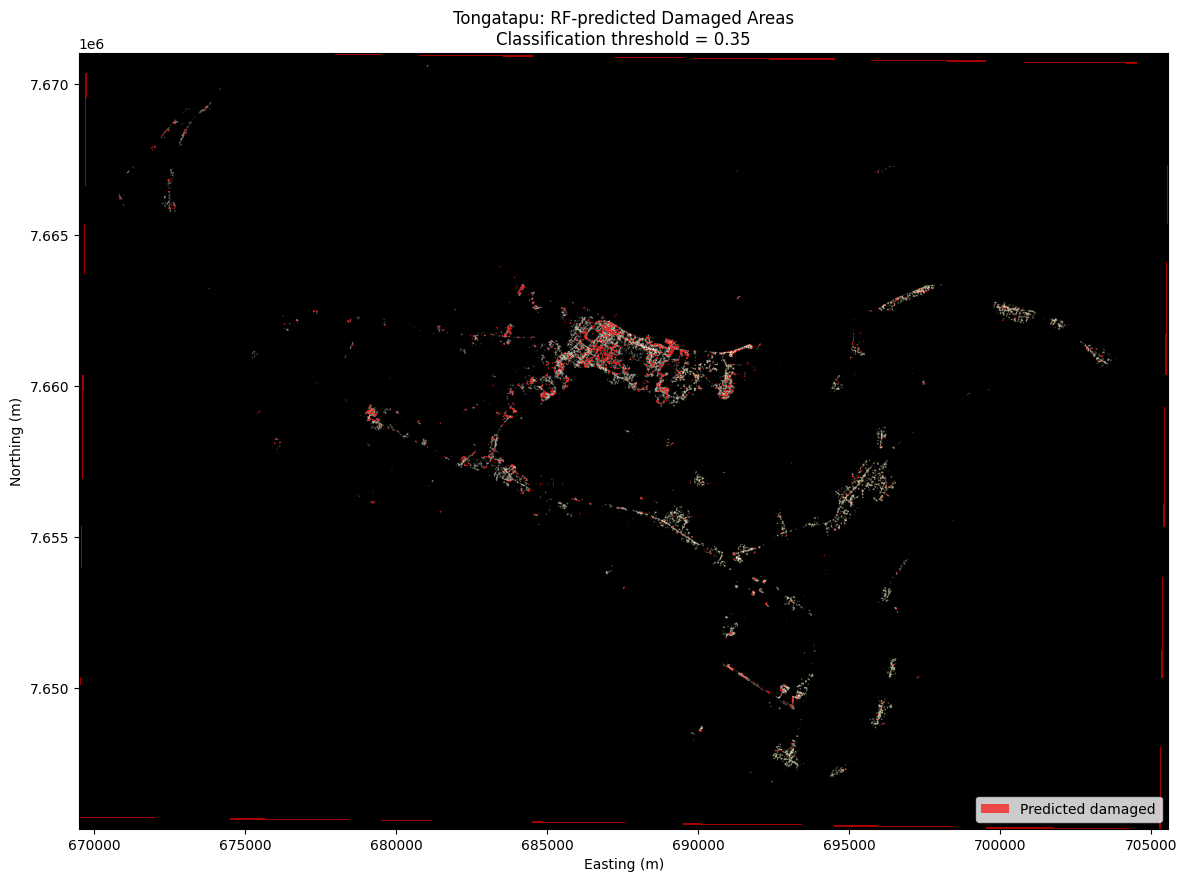

Map saved: /content/tongatapu_rf_damage_map.png
Map CRS: EPSG:32701


In [15]:
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba

MAP_PATH = "/content/tongatapu_rf_damage_map.png"

with rasterio.open(TIF_PATH) as src:
    # Post-event S2 bands in the 24-band stack:
    # 1-based band 11 = B2, 12 = B3, 13 = B4.
    blue = src.read(11).astype(np.float32)
    green = src.read(12).astype(np.float32)
    red = src.read(13).astype(np.float32)

    input_nodata = src.nodata
    bounds = src.bounds

    rgb_raw = np.stack([red, green, blue], axis=-1)

    valid_rgb = (
        np.isfinite(rgb_raw).all(axis=-1)
        & (rgb_raw != input_nodata).all(axis=-1)
    )

    # Estimate display stretch from valid pixels only.
    if not np.any(valid_rgb):
        raise ValueError("No valid post-event RGB pixels found.")

    rgb_values = rgb_raw[valid_rgb]
    low = np.percentile(rgb_values, 2)
    high = np.percentile(rgb_values, 98)

    if high <= low:
        raise ValueError("Unable to calculate a valid RGB stretch.")

    rgb = np.clip((rgb_raw - low) / (high - low), 0, 1)
    rgb[~valid_rgb] = 0

with rasterio.open(CLASS_PATH) as src:
    damage_class = src.read(1)
    class_nodata = src.nodata
    class_bounds = src.bounds
    class_crs = src.crs

assert bounds == class_bounds, "Input and prediction raster bounds differ."

damaged_mask = damage_class == 1
damaged_rgba = np.zeros(
    (*damaged_mask.shape, 4),
    dtype=np.float32,
)
damaged_rgba[damaged_mask] = to_rgba("red", alpha=0.65)

fig, ax = plt.subplots(figsize=(12, 10))

extent = (
    bounds.left,
    bounds.right,
    bounds.bottom,
    bounds.top,
)

ax.imshow(rgb, extent=extent, origin="upper")
ax.imshow(
    damaged_rgba,
    extent=extent,
    origin="upper",
    interpolation="nearest",
)

ax.set_title(
    "Tongatapu: RF-predicted Damaged Areas\n"
    f"Classification threshold = {THRESHOLD:.2f}"
)
ax.set_xlabel("Easting (m)")
ax.set_ylabel("Northing (m)")

from matplotlib.patches import Patch
ax.legend(
    handles=[
        Patch(facecolor="red", alpha=0.65, label="Predicted damaged")
    ],
    loc="lower right",
)

plt.tight_layout()
plt.savefig(MAP_PATH, dpi=200, bbox_inches="tight")
plt.show()

print("Map saved:", MAP_PATH)
print("Map CRS:", class_crs)

### Download the results

In [16]:
import zipfile
from google.colab import files

OUTPUT_FILES = [
    PROB_PATH,
    CLASS_PATH,
    MAP_PATH,
]

for path in OUTPUT_FILES:
    if not os.path.exists(path):
        raise FileNotFoundError(f"Expected output missing: {path}")

ZIP_PATH = "/content/tongatapu_rf_prediction_outputs.zip"

with zipfile.ZipFile(
    ZIP_PATH, "w", compression=zipfile.ZIP_DEFLATED
) as zf:
    for path in OUTPUT_FILES:
        zf.write(path, arcname=os.path.basename(path))

print(f"ZIP size: {os.path.getsize(ZIP_PATH) / (1024**2):.2f} MB")
files.download(ZIP_PATH)

ZIP size: 0.87 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>